In [12]:
import numpy as np
import pandas as py
import matplotlib.pyplot as mp

In [13]:
df = py.read_csv('data/processed.csv')

In [14]:
df['timestamp'] = py.to_datetime(df['timestamp'])
df['days'] = df['timestamp'].dt.day
print(f'Timestamp: {df["timestamp"]}\n Days: {df["days"]}\n')

Timestamp: 0     2025-01-01
1     2025-01-02
2     2025-01-03
3     2025-01-04
4     2025-01-05
         ...    
361   2025-12-28
362   2025-12-29
363   2025-12-30
364   2025-12-31
365   2026-01-01
Name: timestamp, Length: 366, dtype: datetime64[us]
 Days: 0       1
1       2
2       3
3       4
4       5
       ..
361    28
362    29
363    30
364    31
365     1
Name: days, Length: 366, dtype: int32



In [16]:
print(f'Columns: {df.columns}\n')
print(f'Head: {df.head()}\n')
print(f'Describe: {df.describe()}\n')
print(f'Info: {df.info()}\n')
print(f'Null Values: {df.isnull().sum()}\n')
print(f'Duplicates: {df.duplicated().sum()}\n')
print(f'Shape: {df.shape}\n')
print(f'Unique Values: {df.nunique()}\n')

Columns: Index(['project', 'article', 'granularity', 'timestamp', 'access', 'agent',
       'views', 'days'],
      dtype='str')

Head:         project                        article granularity  timestamp  \
0  en.wikipedia  Python_(programming_language)       daily 2025-01-01   
1  en.wikipedia  Python_(programming_language)       daily 2025-01-02   
2  en.wikipedia  Python_(programming_language)       daily 2025-01-03   
3  en.wikipedia  Python_(programming_language)       daily 2025-01-04   
4  en.wikipedia  Python_(programming_language)       daily 2025-01-05   

       access       agent  views  days  
0  all-access  all-agents   5954     1  
1  all-access  all-agents   7245     2  
2  all-access  all-agents   7286     3  
3  all-access  all-agents   6492     4  
4  all-access  all-agents   6804     5  

Describe:                  timestamp         views        days
count                  366    366.000000  366.000000
mean   2025-07-02 12:00:00  10383.622951   15.680328
min    20

#### Seasonality Check

In [17]:
d = dict()
for view in range(1, len(df['views'].values), 7):
    d[view] = df["views"].values[view]

df_views = py.DataFrame(list(d.items()), columns=['Week(+7)', 'Views'])
df_views.head()


,Week(+7),Views
0,1,7245
1,8,12785
2,15,13290
3,22,9803
4,29,9338


In [18]:
df['days'] = py.to_datetime('2025-01-01') + py.to_timedelta(df['days'] - 1, unit='D')
df['days'] = df['days'].dt.day_name()

In [21]:
df['days'].head()

0    Wednesday
1     Thursday
2       Friday
3     Saturday
4       Sunday
Name: days, dtype: str

In [ ]:
# Day wise comparison of views        
df.groupby('days')['views'].mean()

days
Friday       10214.218182
Monday       10726.604167
Saturday     11012.229167
Sunday       10139.375000
Thursday      9872.779661
Tuesday      10941.416667
Wednesday    10013.133333
Name: views, dtype: float64

In [25]:
df['weekday'] = df['timestamp'].dt.day_name()
df['weekday'].head()

0    Wednesday
1     Thursday
2       Friday
3     Saturday
4       Sunday
Name: weekday, dtype: str

In [ ]:
# Day wise comparison of views        
df.groupby('weekday')['views'].mean().reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])

weekday
Monday       10399.307692
Tuesday      10596.173077
Wednesday    10771.716981
Thursday     11595.773585
Friday       11032.403846
Saturday      9329.057692
Sunday        8930.153846
Name: views, dtype: float64

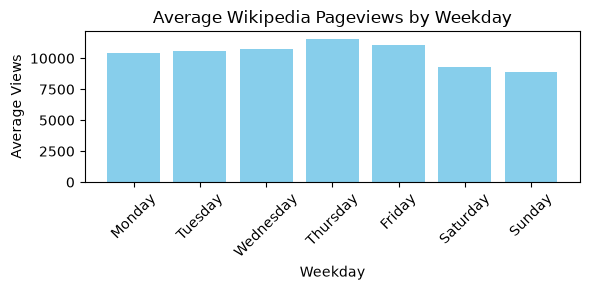

In [37]:
weekdays_views = df.groupby('weekday')['views'].mean().reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']).index

weekdays = df.groupby('weekday')['views'].mean().reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']).values


mp.figure(figsize=(6,3))
mp.bar(weekdays_views, weekdays, color='skyblue')
mp.xlabel('Weekday')
mp.ylabel('Average Views')
mp.title('Average Wikipedia Pageviews by Weekday')
mp.xticks(rotation=45)
mp.tight_layout()
mp.show()

## Weekly Seasonality Analysis

We grouped the Wikipedia page views by **day of the week** and calculated the average views for each day.

| Weekday | Average Views |
|---|---:|
| Monday | 10,399 |
| Tuesday | 10,596 |
| Wednesday | 10,772 |
| Thursday | **11,596** |
| Friday | 11,032 |
| Saturday | 9,329 |
| Sunday | **8,930** |

### Findings

- Views generally **increase from Monday to Thursday**.
- **Thursday has the highest average views** (~11,596).
- Views start decreasing from Friday.
- **Sunday has the lowest average views** (~8,930).
- Thursday has roughly **30% more views than Sunday**.
- This indicates the presence of **weekly seasonality** in the page-view data.

### Conclusion

> The data shows evidence of **weekly seasonality**, where Wikipedia page views tend to be higher during weekdays and lower during weekends, with Thursday showing the highest average and Sunday the lowest.

The weekly period is **7 days**, so this pattern may be useful as a feature when building our forecasting model.

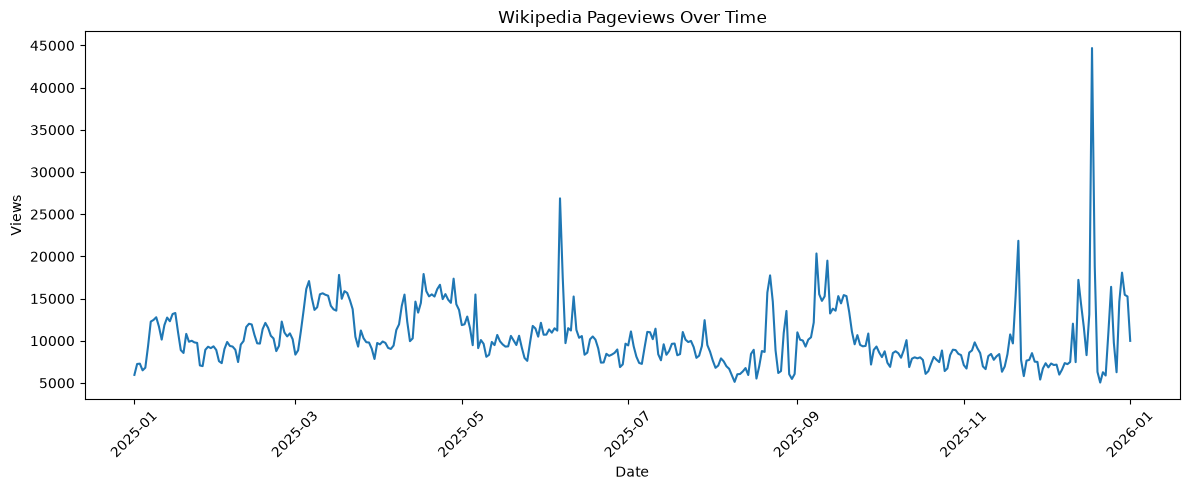

In [39]:
mp.figure(figsize=(12,5))
# mp.plot(df['days'], df['views'])
# mp.xlabel('Timestamp')
# mp.ylabel('Views')
# mp.show()
mp.plot(df['timestamp'], df['views'])

mp.xlabel('Date')
mp.ylabel('Views')
mp.title('Wikipedia Pageviews Over Time')

mp.xticks(rotation=45)
mp.tight_layout()
mp.show()

### Rolling data visualization (weekly)


## Trend Analysis — 7-Day Rolling Mean

We used a **7-day rolling mean** to smooth out daily fluctuations and observe the underlying trend in Wikipedia page views.

### Findings

- Views show **no clear overall increasing or decreasing trend** throughout the year.
- The average level of views **changes across different periods**.
- There are noticeable increases around **March, April, August–September, and December**.
- There are noticeable decreases around **June–July and October–November**.
- The data contains several **large spikes**, especially one around December reaching ~45,000 views.
- The 7-day rolling mean confirms that the dataset is **highly variable rather than following a simple linear trend**.

### Conclusion

> The page views do not show a strong long-term trend. Instead, they fluctuate over time with several periods of higher/lower activity and occasional large spikes.

**Next:** Investigate the unusual spikes using **outlier/anomaly analysis**.

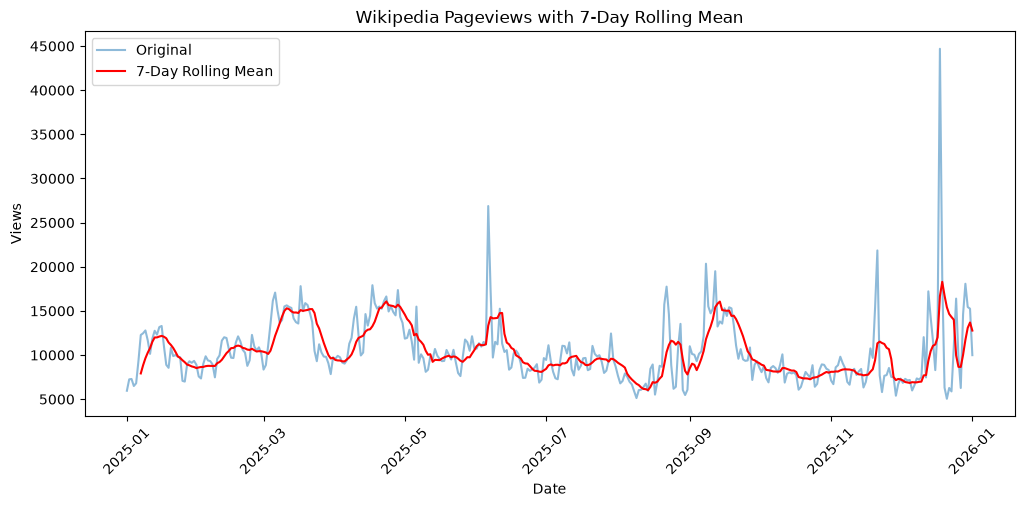

In [40]:
rolling_mean = df['views'].rolling(window=7).mean()
mp.figure(figsize=(12,5))
mp.plot(df['timestamp'], df['views'], label='Original', alpha=0.5)
mp.plot(df['timestamp'], rolling_mean, label='7-Day Rolling Mean', color='red')
mp.xlabel('Date')
mp.ylabel('Views')
mp.title('Wikipedia Pageviews with 7-Day Rolling Mean')
mp.legend()
mp.xticks(rotation=45)
mp.show()

### Boxplot to check for ## Outlier Analysis

We used the **IQR (Interquartile Range) method** and a boxplot to identify unusual page-view observations.

### Findings

- The median daily page views are around **10,000**.
- Most observations lie within the normal IQR range.
- Several observations exceed the **upper IQR bound (~17,500 views)**.
- Most detected outliers are **high-view spikes** rather than unusually low values.
- The largest observed spike is around **45,000 views**.

### Conclusion

> The dataset contains several high-value outliers. These should not be removed automatically because they may represent genuine events or temporary increases in Wikipedia interest rather than data errors.

**Next:** Investigate the dates corresponding to these outliers to determine whether they represent genuine events or anomalies.outliers

/tmp/ipykernel_31772/499902452.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  mp.boxplot(df['views'], vert=False)


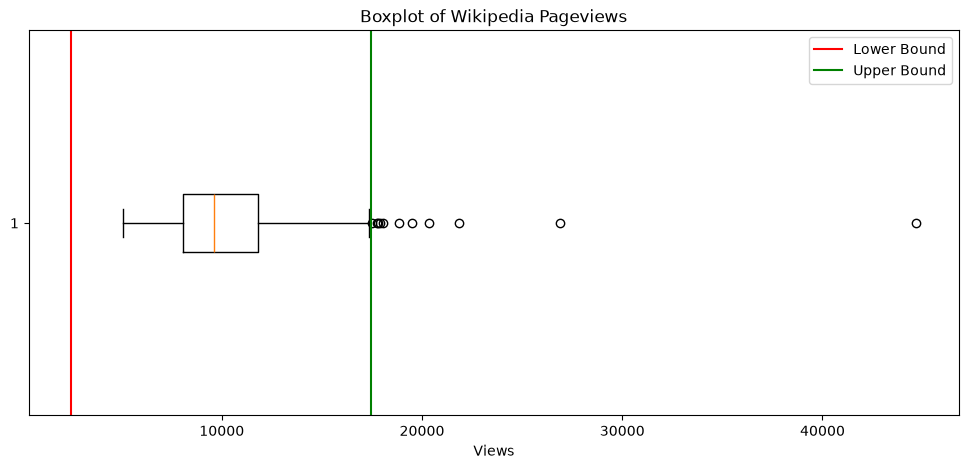

In [44]:
q0 = df['views'].quantile(0.25)
q1 = df['views'].quantile(0.75)
iqr = q1 - q0
lower_bound = q0 - 1.5 * iqr
upper_bound = q1 + 1.5 * iqr

mp.figure(figsize=(12,5))
mp.boxplot(df['views'], vert=False)
mp.title('Boxplot of Wikipedia Pageviews')
mp.xlabel('Views')
mp.axvline(lower_bound, color='red', linestyle='-', label='Lower Bound')
mp.axvline(upper_bound, color='green', linestyle='-', label='Upper Bound')
mp.legend()
mp.show()

In [46]:
outliers = df[(df['views'] < lower_bound) | (df['views'] > upper_bound)].sort_values('days')
outliers[['days', 'views']]

,days,views
75,Friday,17804
106,Friday,17911
156,Monday,26878
351,Saturday,44692
254,Sunday,19495
352,Sunday,18840
157,Tuesday,17492
324,Tuesday,21850
233,Wednesday,17749
250,Wednesday,20344


In [ ]:
df['date'] = py.to_datetime('2025-01-01') + py.to_timedelta(df.index, unit='D')

In [49]:
df[['date', 'days', 'views']].head()

,date,days,views
0,2025-01-01,Wednesday,5954
1,2025-01-02,Thursday,7245
2,2025-01-03,Friday,7286
3,2025-01-04,Saturday,6492
4,2025-01-05,Sunday,6804


In [50]:
outliers[['date', 'views']]

KeyError: "['date'] not in index"